
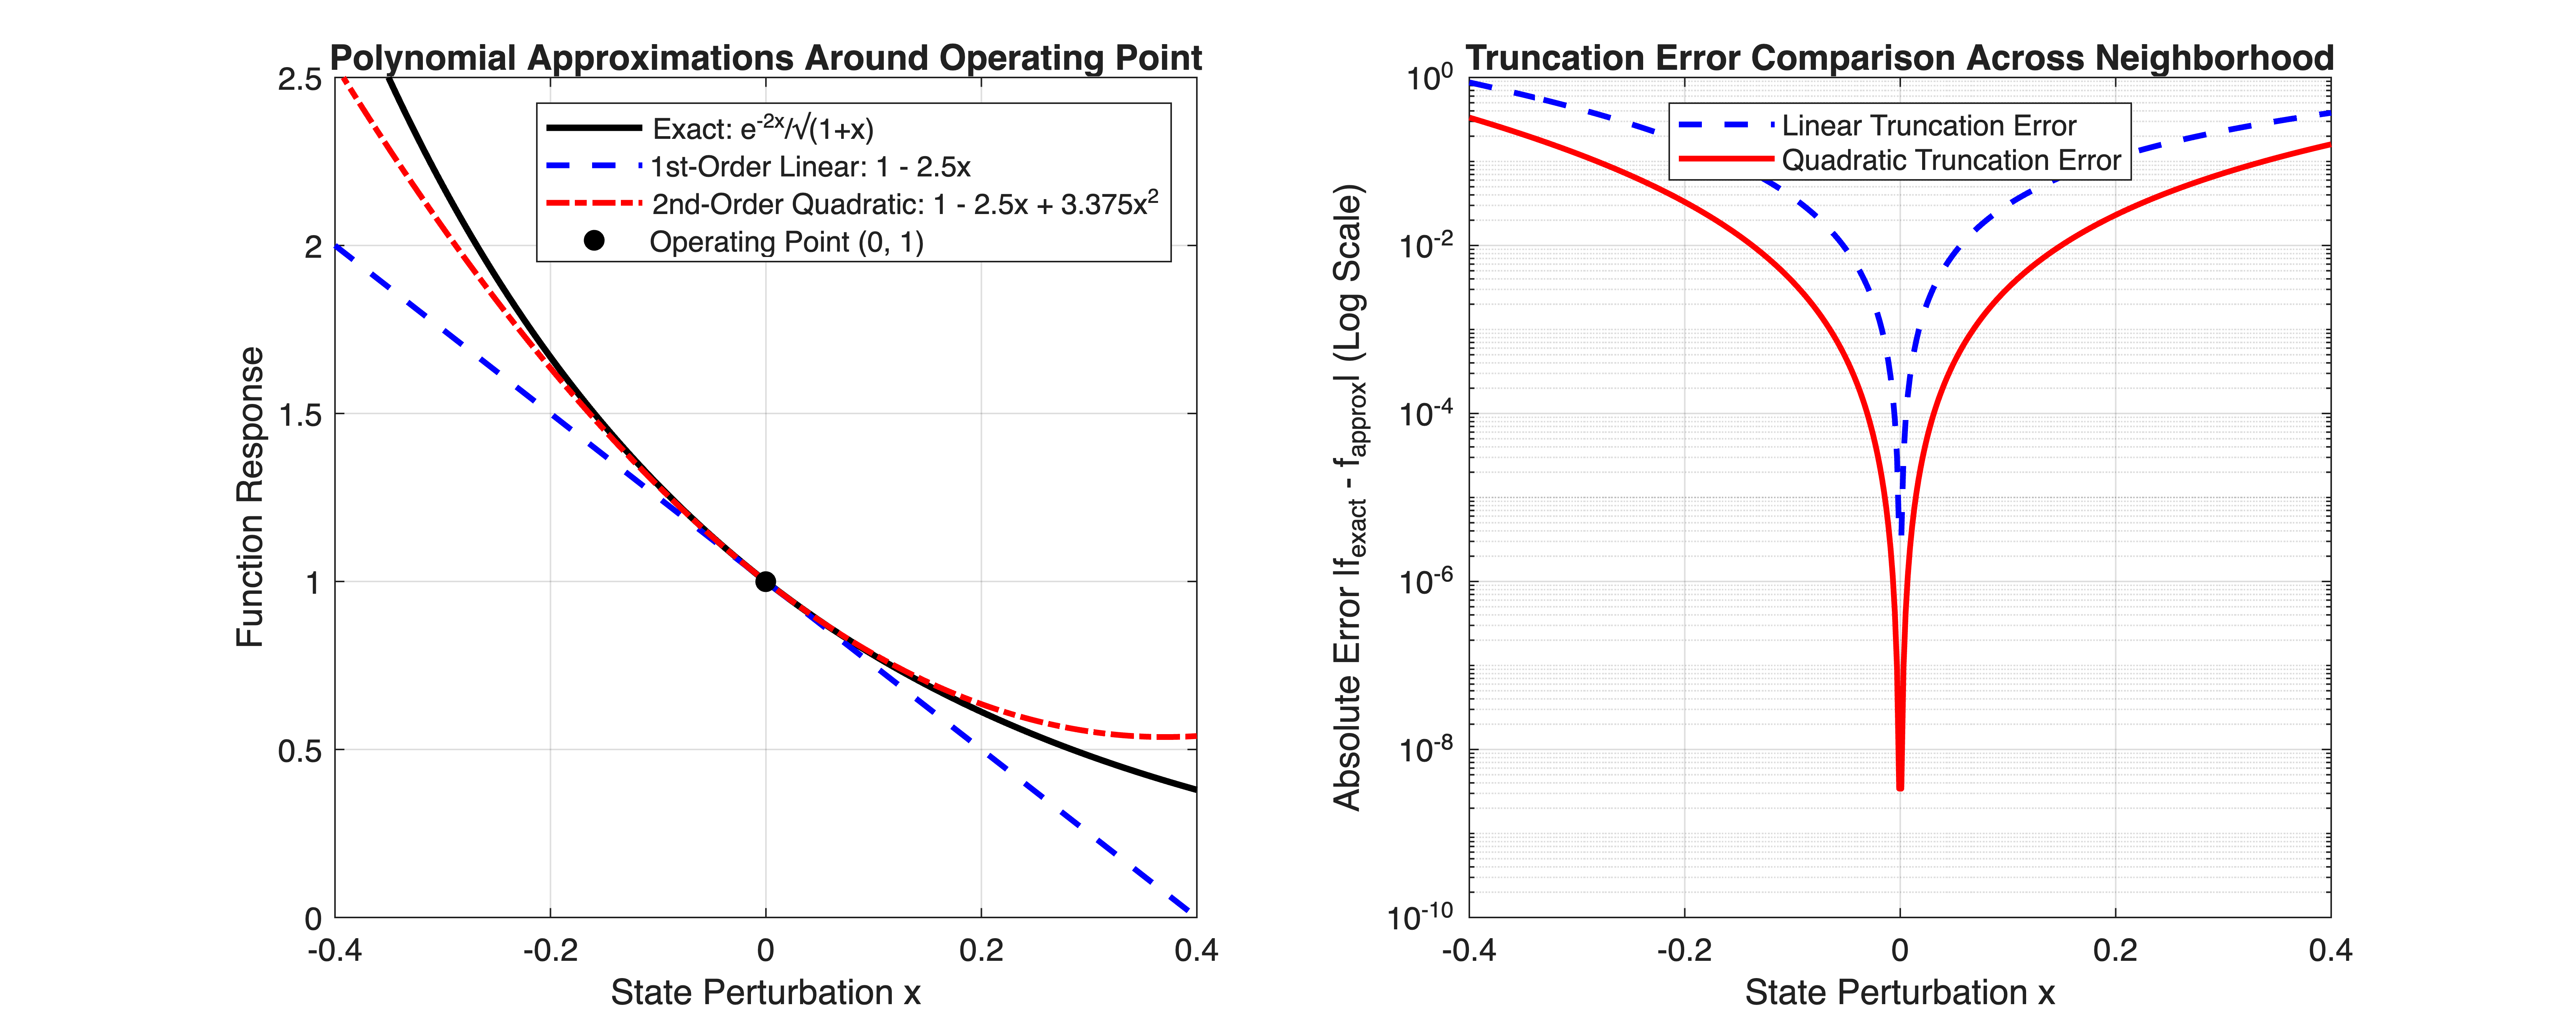

In [1]:
%% MIT 18.01 Lecture 9: Linear and Quadratic Approximations Simulation
% Mathematical Tool Application: Used for local operating-point linearization
% of nonlinear plant dynamics, Hessian curvature evaluation in trajectory optimization,
% and error budgeting for embedded algorithm precision.


clear; clc; close all;


%% Part 1: Linear vs. Quadratic Approximation of f(x) = exp(-2*x) / sqrt(1+x)
% Exact function from Lecture 9 Example 2 & Example 5
f_exact = @(x) exp(-2 * x) ./ sqrt(1 + x);


% Approximations derived algebraically in lecture around x0 = 0:
% Linear:    f(x) approx 1 - (5/2)*x
% Quadratic: f(x) approx 1 - (5/2)*x + (27/8)*x^2
f_linear = @(x) 1 - 2.5 * x;
f_quadratic = @(x) 1 - 2.5 * x + (27/8) * (x.^2);


% Domain of evaluation near operating point x0 = 0
x_domain = linspace(-0.4, 0.4, 400);


y_exact = f_exact(x_domain);
y_linear = f_linear(x_domain);
y_quadratic = f_quadratic(x_domain);


% Truncation errors
err_linear = abs(y_exact - y_linear);
err_quadratic = abs(y_exact - y_quadratic);


figure('Color', 'w', 'Position', [100, 100, 1200, 480]);


subplot(1, 2, 1);
plot(x_domain, y_exact, 'k-', 'LineWidth', 2.0, 'DisplayName', 'Exact: e^{-2x}/\surd(1+x)'); hold on;
plot(x_domain, y_linear, 'b--', 'LineWidth', 1.8, 'DisplayName', '1st-Order Linear: 1 - 2.5x');
plot(x_domain, y_quadratic, 'r-.', 'LineWidth', 1.8, 'DisplayName', '2nd-Order Quadratic: 1 - 2.5x + 3.375x^2');
plot(0, 1, 'ko', 'MarkerFaceColor', 'k', 'DisplayName', 'Operating Point (0, 1)');


grid on;
xlabel('State Perturbation x');
ylabel('Function Response');
title('Polynomial Approximations Around Operating Point');
legend('Location', 'northeast');
xlim([-0.4, 0.4]); ylim([0.0, 2.5]);


subplot(1, 2, 2);
semilogy(x_domain, err_linear, 'b--', 'LineWidth', 1.8, 'DisplayName', 'Linear Truncation Error'); hold on;
semilogy(x_domain, err_quadratic, 'r-', 'LineWidth', 1.8, 'DisplayName', 'Quadratic Truncation Error');


grid on;
xlabel('State Perturbation x');
ylabel('Absolute Error |f_{exact} - f_{approx}| (Log Scale)');
title('Truncation Error Comparison Across Neighborhood');
legend('Location', 'north');
xlim([-0.4, 0.4]);


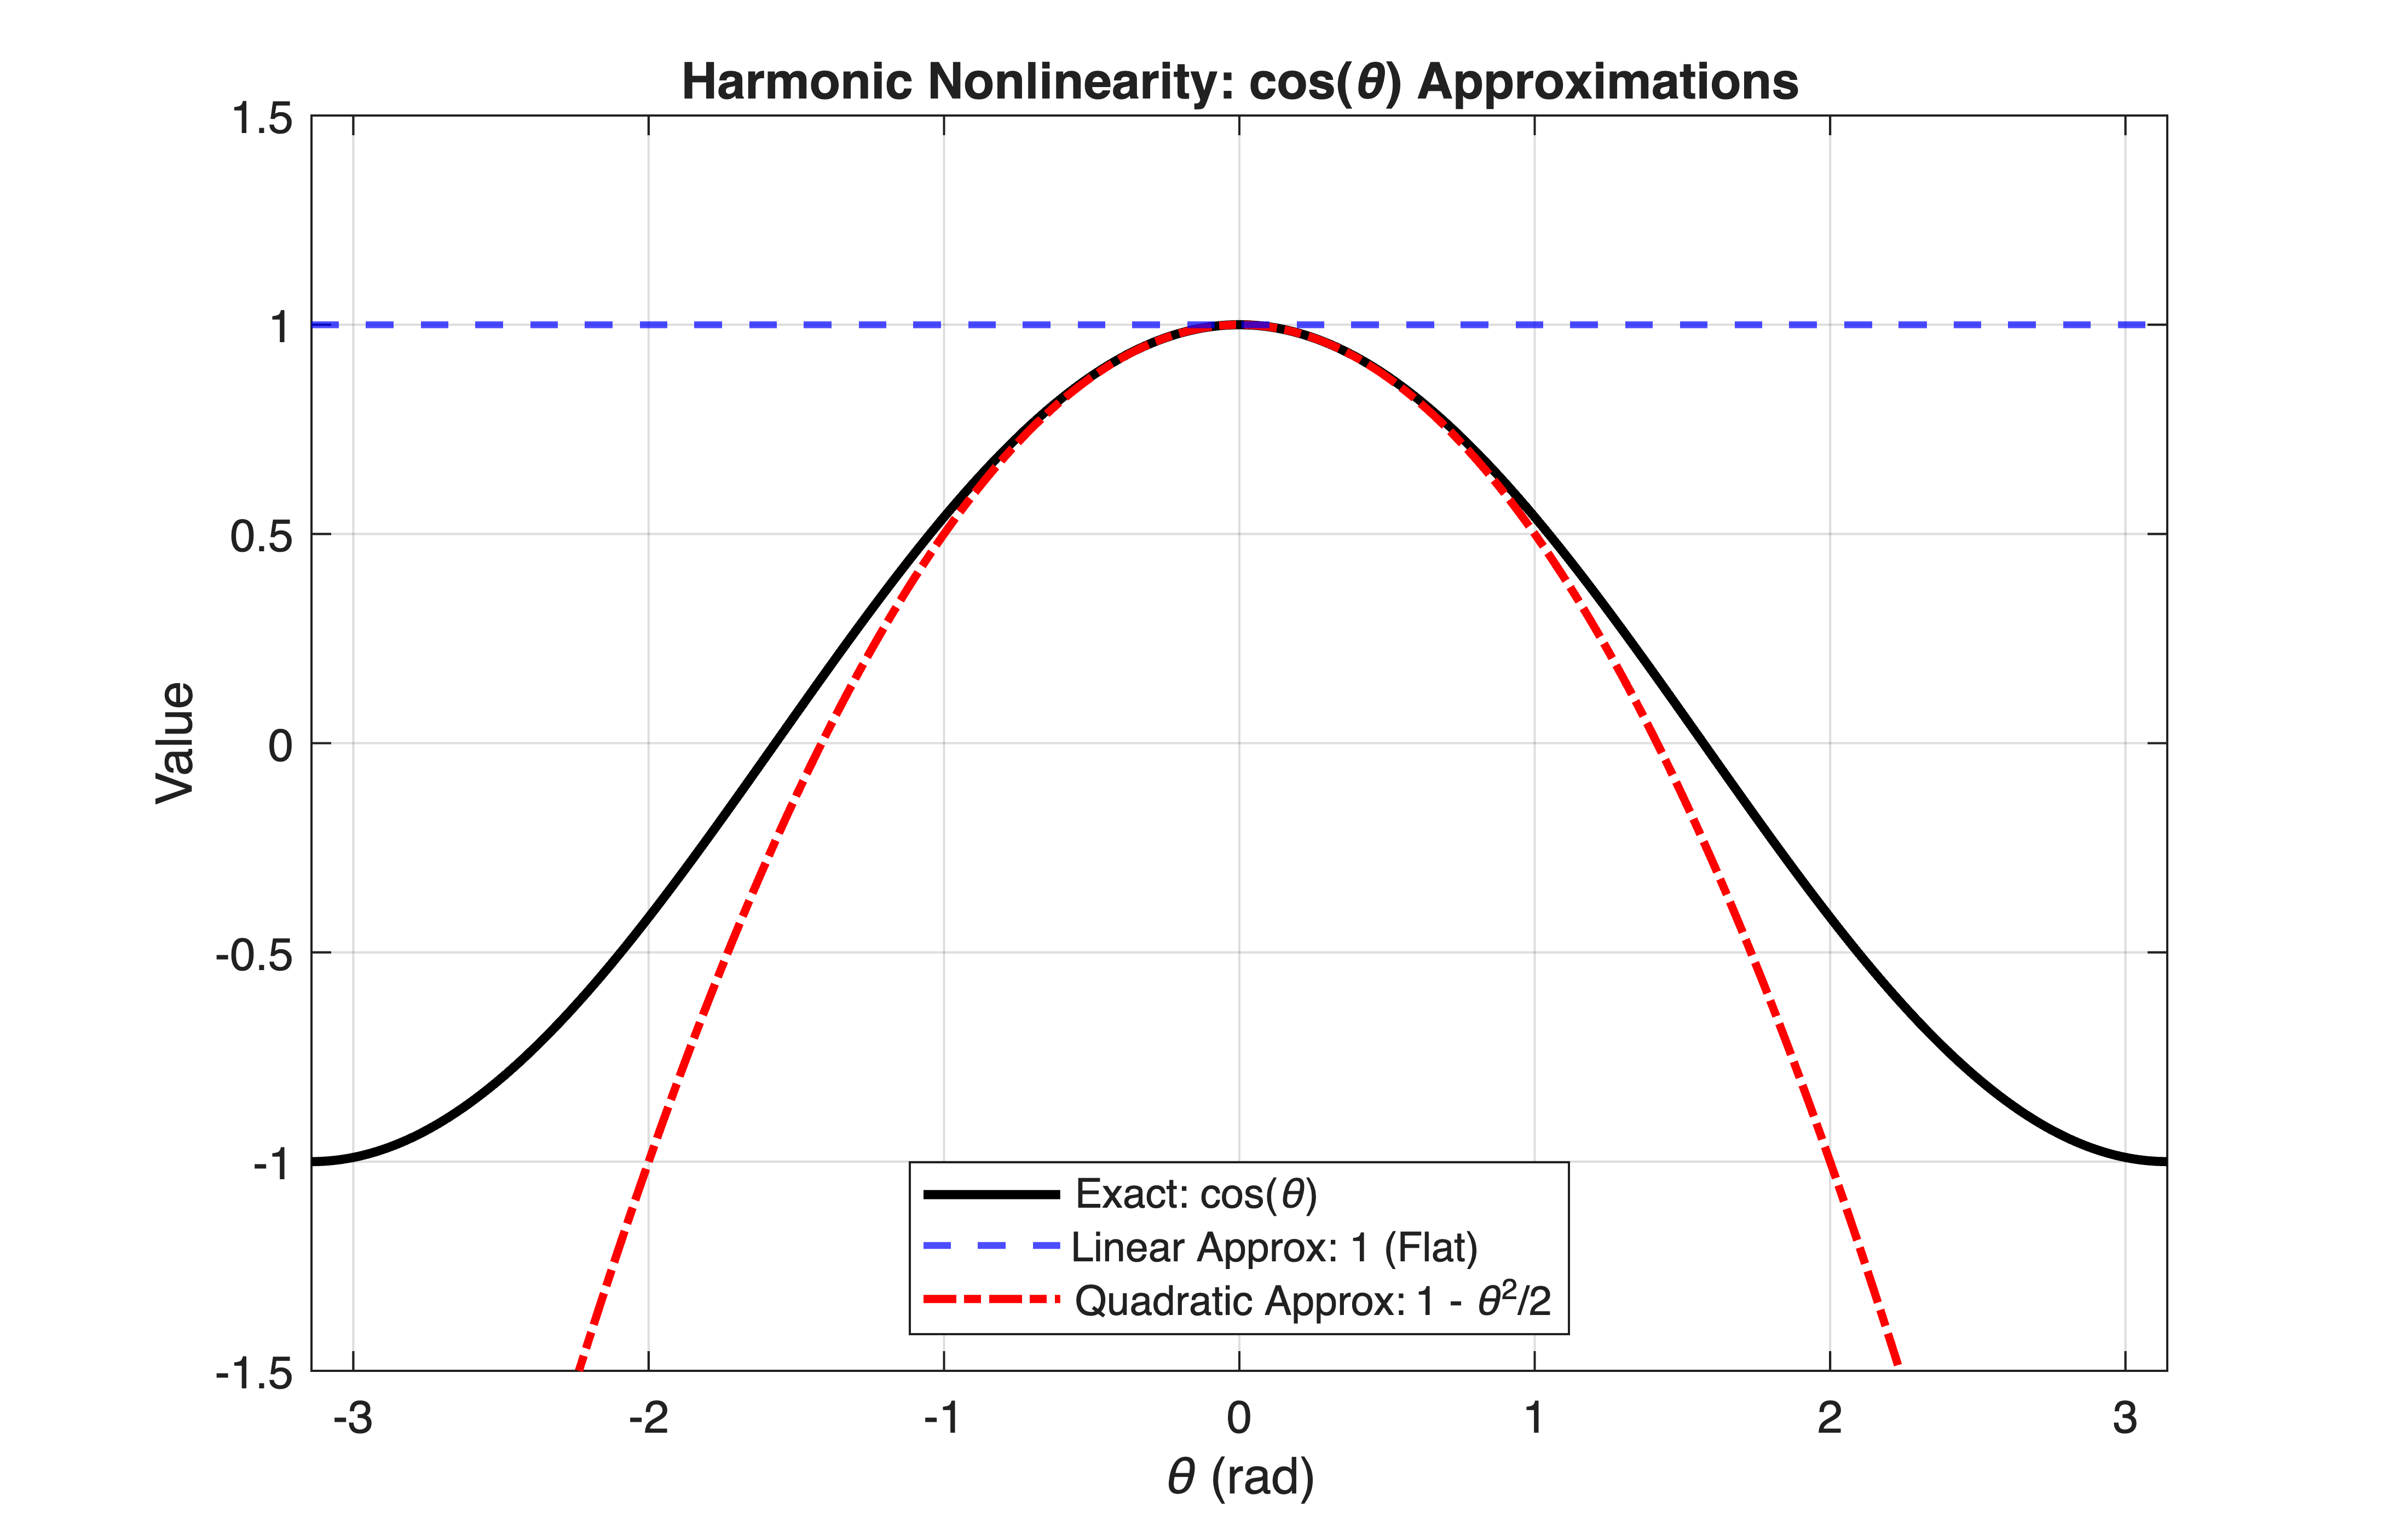

In [2]:
%% Part 2: Harmonic Restoring Approximation: cos(x)
figure('Color', 'w', 'Position', [150, 150, 700, 450]);
theta = linspace(-pi, pi, 400);
plot(theta, cos(theta), 'k-', 'LineWidth', 2, 'DisplayName', 'Exact: cos(\theta)'); hold on;
yline(1, 'b--', 'LineWidth', 1.5, 'DisplayName', 'Linear Approx: 1 (Flat)');
plot(theta, 1 - 0.5 * theta.^2, 'r-.', 'LineWidth', 1.8, 'DisplayName', 'Quadratic Approx: 1 - \theta^2/2');


grid on;
xlim([-pi, pi]); ylim([-1.5, 1.5]);
xlabel('\theta (rad)');
ylabel('Value');
title('Harmonic Nonlinearity: cos(\theta) Approximations');
legend('Location', 'south');